In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import get_cmap
import pandas as pd
from tools.dataModels.measurements import Measurements
import multiprocessing
from tools.dataAPI.datamodel import DataModel
import functools
import os

import warnings


output_final = []
for i in range(2, 16):
    output = []
    for j in range(1, 6):
        res = []
        # print(res)
        from_sim = f"/Users/mratman1/Desktop/BacteriaRevision2026/spontaneousSpatialSorting/workspace/simulations_eqdivtime/asp{i}/run{j}"
        files_from_sim = sorted([
            f for f in os.listdir(from_sim)
            if not f.startswith('._') and not f.startswith('.')
        ])
        for file in files_from_sim:
            dataPath = os.path.join(from_sim, file)
            opts, times = DataModel.extract_times(dataPath)
            
            time = max(times)
            
            df = pd.read_csv(f"{dataPath}/{time}.csv", header=0)
            data = Measurements(dataPath=dataPath, time=time)
            H = data.Heterozygosity_global(touching=True)
            
            

            res.append(H)
            
            
        output.append(res)
    output_final.append(output)


print("output_final structure:")


averages = []
std_deviations = []

for data in output_final:
    avg = [np.mean(res) for res in data]  
    std_dev = [np.std(res) for res in data]  
    averages.append(avg)
    std_deviations.append(std_dev)

print("Averages:", averages)
print("Standard Deviations:", std_deviations)

num_lines = len(averages)

aspects = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
aspects_plotted = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


heterozygosity_matrix = np.full((len(aspects), len(aspects)), np.nan)  
for i in range(len(aspects)):
    for j in range(len(aspects)):
        try:
            heterozygosity_matrix[i, j] = averages[i][j]
        except IndexError:
            continue  



output_final structure:
Averages: [[np.float64(0.13595546821762722), np.float64(0.1361291850586528), np.float64(0.13665845637815974), np.float64(0.12913388450194516), np.float64(0.13139105576834198)], [np.float64(0.13751766463690526), np.float64(0.13974367061631113), np.float64(0.14202510506157287), np.float64(0.1314646536856217), np.float64(0.1312888664185485)], [np.float64(0.15612875756848862), np.float64(0.15070635762313014), np.float64(0.15535499367106803), np.float64(0.14714693666440065), np.float64(0.15170290331472952)], [np.float64(0.15957610260570357), np.float64(0.16445304884561912), np.float64(0.1708438310191946), np.float64(0.15810435376994472), np.float64(0.1610349373254827)], [np.float64(0.16828066150512397), np.float64(0.1685911668524677), np.float64(0.17349125585422032), np.float64(0.16887446426206112), np.float64(0.16976855573522392)], [np.float64(0.169199235653934), np.float64(0.1755966736532905), np.float64(0.17955788274114073), np.float64(0.1686600979602295), np.floa

## Saving to CSV

In [4]:
# import numpy as np
# import pandas as pd
# import os
# import matplotlib.pyplot as plt




# averages = []
# std_deviations = []

# for data in output_final:
#     avg = [np.mean(res) for res in data]  
#     std_dev = [np.std(res) for res in data]  
#     averages.append(avg)
#     std_deviations.append(std_dev)


# df_averages = pd.DataFrame(averages, index=[f"Aspect_{i}" for i in range(2, 16)], columns=[f"Run_{i}" for i in range(1, 6)])
# df_std_devs = pd.DataFrame(std_deviations, index=[f"Aspect_{i}" for i in range(2, 16)], columns=[f"Run_{i}" for i in range(1, 6)])


# df_averages.to_csv("heterozygosity_averages.csv", index=True)
# df_std_devs.to_csv("heterozygosity_std_devs.csv", index=True)


# print("Averages saved to heterozygosity_averages.csv")
# print("Standard deviations saved to heterozygosity_std_devs.csv")


# num_lines = len(averages)
# aspects = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


# heterozygosity_matrix = np.full((len(aspects), len(aspects)), np.nan)  
# for i in range(len(aspects)):
#     for j in range(len(aspects)):
#         try:
#             heterozygosity_matrix[i, j] = averages[i][j]
#         except IndexError:
#             continue  


# plt.figure(figsize=(8, 6))
# plt.imshow(heterozygosity_matrix, interpolation='nearest', cmap='viridis', origin='lower')
# plt.colorbar(label='Average Heterozygosity')

# plt.title('Heatmap of Average Heterozygosity by Aspect Ratios', fontsize=16)
# plt.xlabel('Aspect Ratio of Population 1')
# plt.ylabel('Aspect Ratio of Population 2')
# plt.xticks(ticks=np.arange(len(aspects)), labels=aspects)
# plt.yticks(ticks=np.arange(len(aspects)), labels=aspects)

# plt.savefig("Heterozygosity_Heatmap.png")
# plt.show()


# plt.figure(figsize=(10, 6), dpi=300)

# color_map = plt.get_cmap('viridis')  


# for i in range(num_lines):
#     color = color_map(i / (num_lines - 1))
#     plt.plot(aspects, averages[i], marker='o', markersize=1, color=color, alpha=1)
#     plt.errorbar(aspects, averages[i], yerr=std_deviations[i], fmt='o', capsize=5, color=color)


# equal_aspects = [averages[i][i] for i in range(len(aspects))]
# equal_aspects_std = [std_deviations[i][i] for i in range(len(aspects))]
# plt.plot(aspects, equal_aspects, marker='o', markersize=5, color='black', linestyle='-', linewidth=2, alpha=1)
# plt.errorbar(aspects, equal_aspects, yerr=equal_aspects_std, fmt='o', capsize=5, color='black')


# sm = plt.cm.ScalarMappable(cmap=color_map, norm=plt.Normalize(vmin=min(aspects), vmax=max(aspects)))
# sm.set_array([])  
# cbar = plt.colorbar(sm)
# cbar.set_label('Aspect Ratio')

# plt.title('Average Heterozygosity at 25000 Cells, Varying Aspect Ratio', fontsize=20)
# plt.xlabel("Aspect Ratio")
# plt.ylabel("Average Heterozygosity")

# plt.savefig("Heterozygosity_Final_Plot.png")
# plt.show()


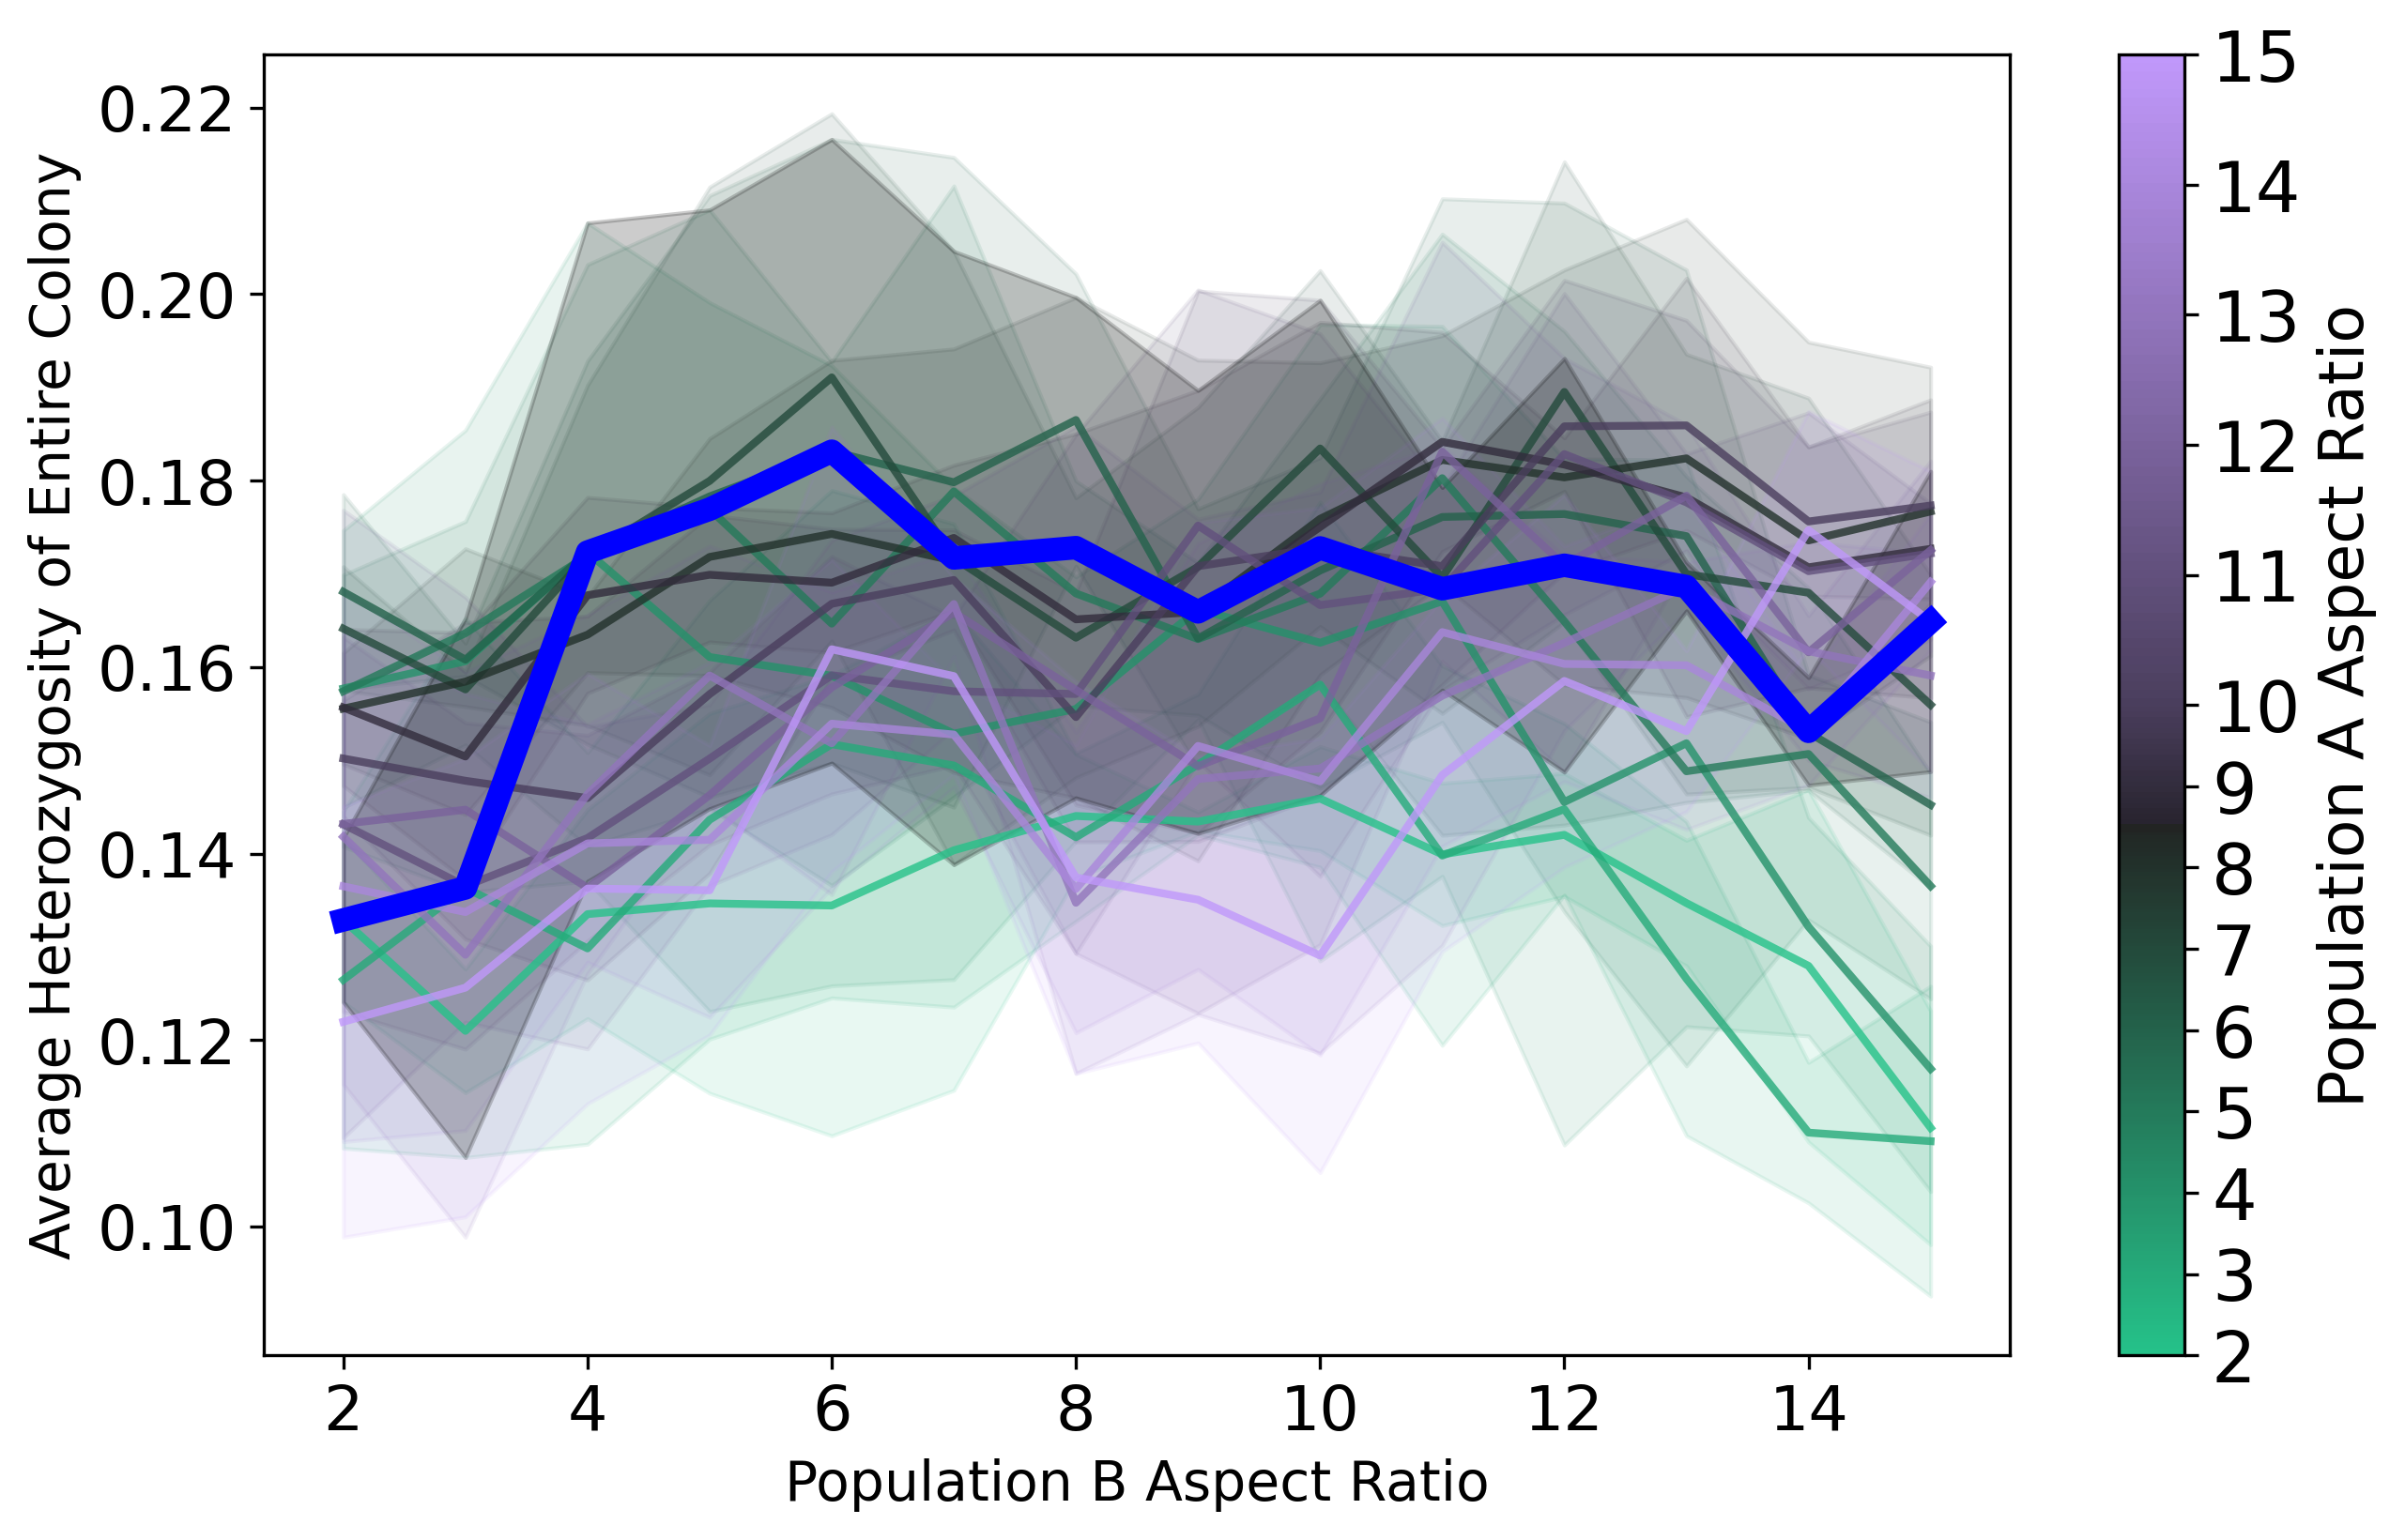

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import colors


class MidpointNormalize(colors.Normalize):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        self.midpoint = midpoint
        super().__init__(vmin, vmax, clip)

    def __call__(self, value, clip=None):
        
        result = np.ma.masked_array(np.interp(value, [self.vmin, self.midpoint, self.vmax], [0, 0.5, 1]))
        return result


plt.rcParams.update({
    'font.size': 14,  
    'xtick.labelsize': 16,  
    'ytick.labelsize': 16,  
    'axes.labelsize': 18,  
    'axes.titlesize': 20,  
    'legend.fontsize': 14,  
})


averages = []
std_deviations = []


for aspect_results in output_final:
    aspect_array = np.array([np.array(run_results) for idx, run_results in enumerate(aspect_results) 
                             if len(run_results) > 0 and not (idx == 1 or idx == 3)])
    
    if aspect_array.size > 0:
        avg = np.mean(aspect_array, axis=0)  
        std_dev = np.std(aspect_array, axis=0)  
    else:
        avg = np.array([])
        std_dev = np.array([])

    averages.append(avg)
    std_deviations.append(std_dev)

num_lines = len(averages)

aspects = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


color_map = sns.diverging_palette(150, 280, s=95, l=70, center="dark", as_cmap=True)  


plt.figure(figsize=(10, 6), dpi=300)


for i in range(num_lines):
    if len(averages[i]) > 0:
        color = color_map((aspects[i] - min(aspects)) / (max(aspects) - min(aspects)))
        plt.plot(aspects, averages[i], linestyle='-', linewidth=2, color=color, alpha=0.8)
        plt.fill_between(
            aspects, 
            averages[i] - std_deviations[i], 
            averages[i] + std_deviations[i], 
            color=color, 
            alpha=0.1  
        )


equal_aspects = [averages[i][i] for i in range(len(aspects)) if len(averages[i]) > i]
equal_aspects_std = [std_deviations[i][i] for i in range(len(aspects)) if len(std_deviations[i]) > i]
plt.plot(aspects, equal_aspects, linestyle='-', linewidth=6, color='blue', alpha=1)
plt.fill_between(
    aspects, 
    np.array(equal_aspects) - np.array(equal_aspects_std), 
    np.array(equal_aspects) + np.array(equal_aspects_std), 
    color='black', 
    alpha=0.2  
)


norm = MidpointNormalize(vmin=min(aspects), vmax=max(aspects), midpoint=10)  
sm = plt.cm.ScalarMappable(cmap=color_map, norm=norm)
sm.set_array([])  


cbar = plt.colorbar(sm, ax=plt.gca(), ticks=np.arange(2, 16, 1))  
cbar.set_label('Population A Aspect Ratio', fontsize=16)
cbar.ax.tick_params(labelsize=18)  


plt.xlabel("Population B Aspect Ratio", fontsize=14)
plt.ylabel("Average Heterozygosity of Entire Colony", fontsize=14)  
plt.tick_params(labelsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.savefig("Heterozygosity_Final_Plot_Centered_Colorbar.png")
plt.show()


# Make (i, j) = (j, i)

output_final structure:
output_final[0] length: 5 - [[np.float64(0.13432882910189475), np.float64(0.11804572443895002), np.float64(0.13659823072690552), np.float64(0.14300164553863032), np.float64(0.13491044206591907), np.float64(0.16677472189567347), np.float64(0.15023221338035866), np.float64(0.1425365885248323), np.float64(0.14993705689771308), np.float64(0.13398832834745067), np.float64(0.13716506664502426), np.float64(0.13576432238001013), np.float64(0.1177975764115669), np.float64(0.10229580869185198)], [np.float64(0.15242930763280352), np.float64(0.13420232922602765), np.float64(0.14834827494657002), np.float64(0.16805755325116378), np.float64(0.1476021525754429), np.float64(0.1686757238015042), np.float64(0.15477311201216057), np.float64(0.15708806954603555), np.float64(0.12620153342978208), np.float64(0.12903492463429406), np.float64(0.12465886059616826), np.float64(0.12867310043991625), np.float64(0.09804496434723278), np.float64(0.13130636351728106), np.float64(0.10374033385

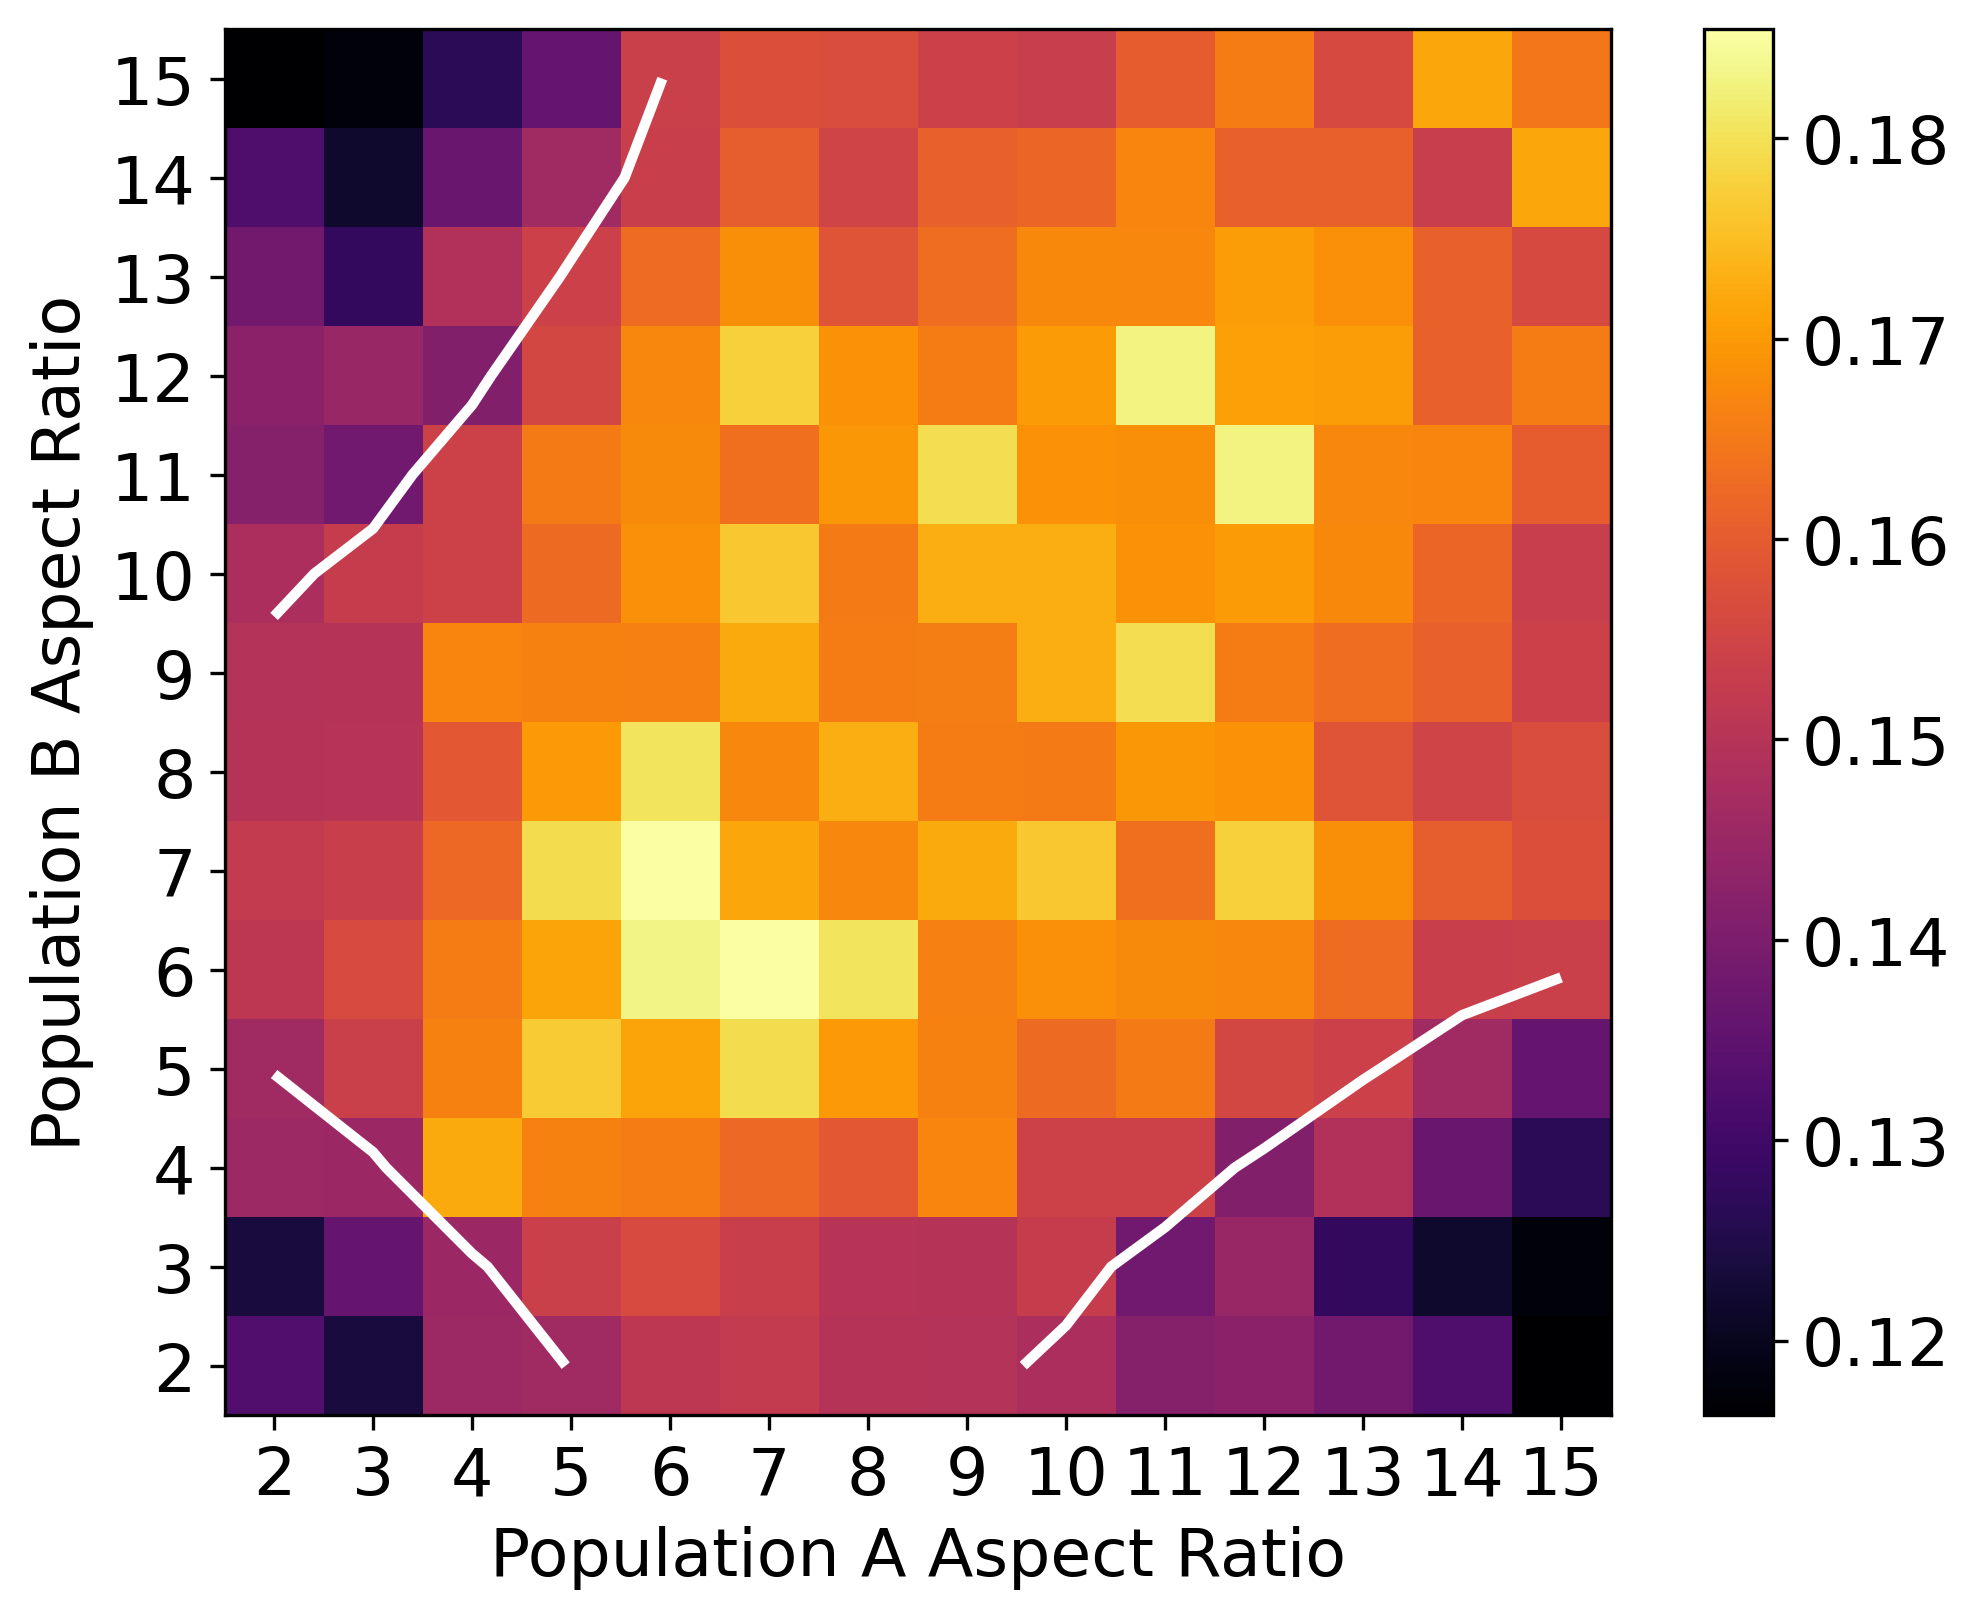

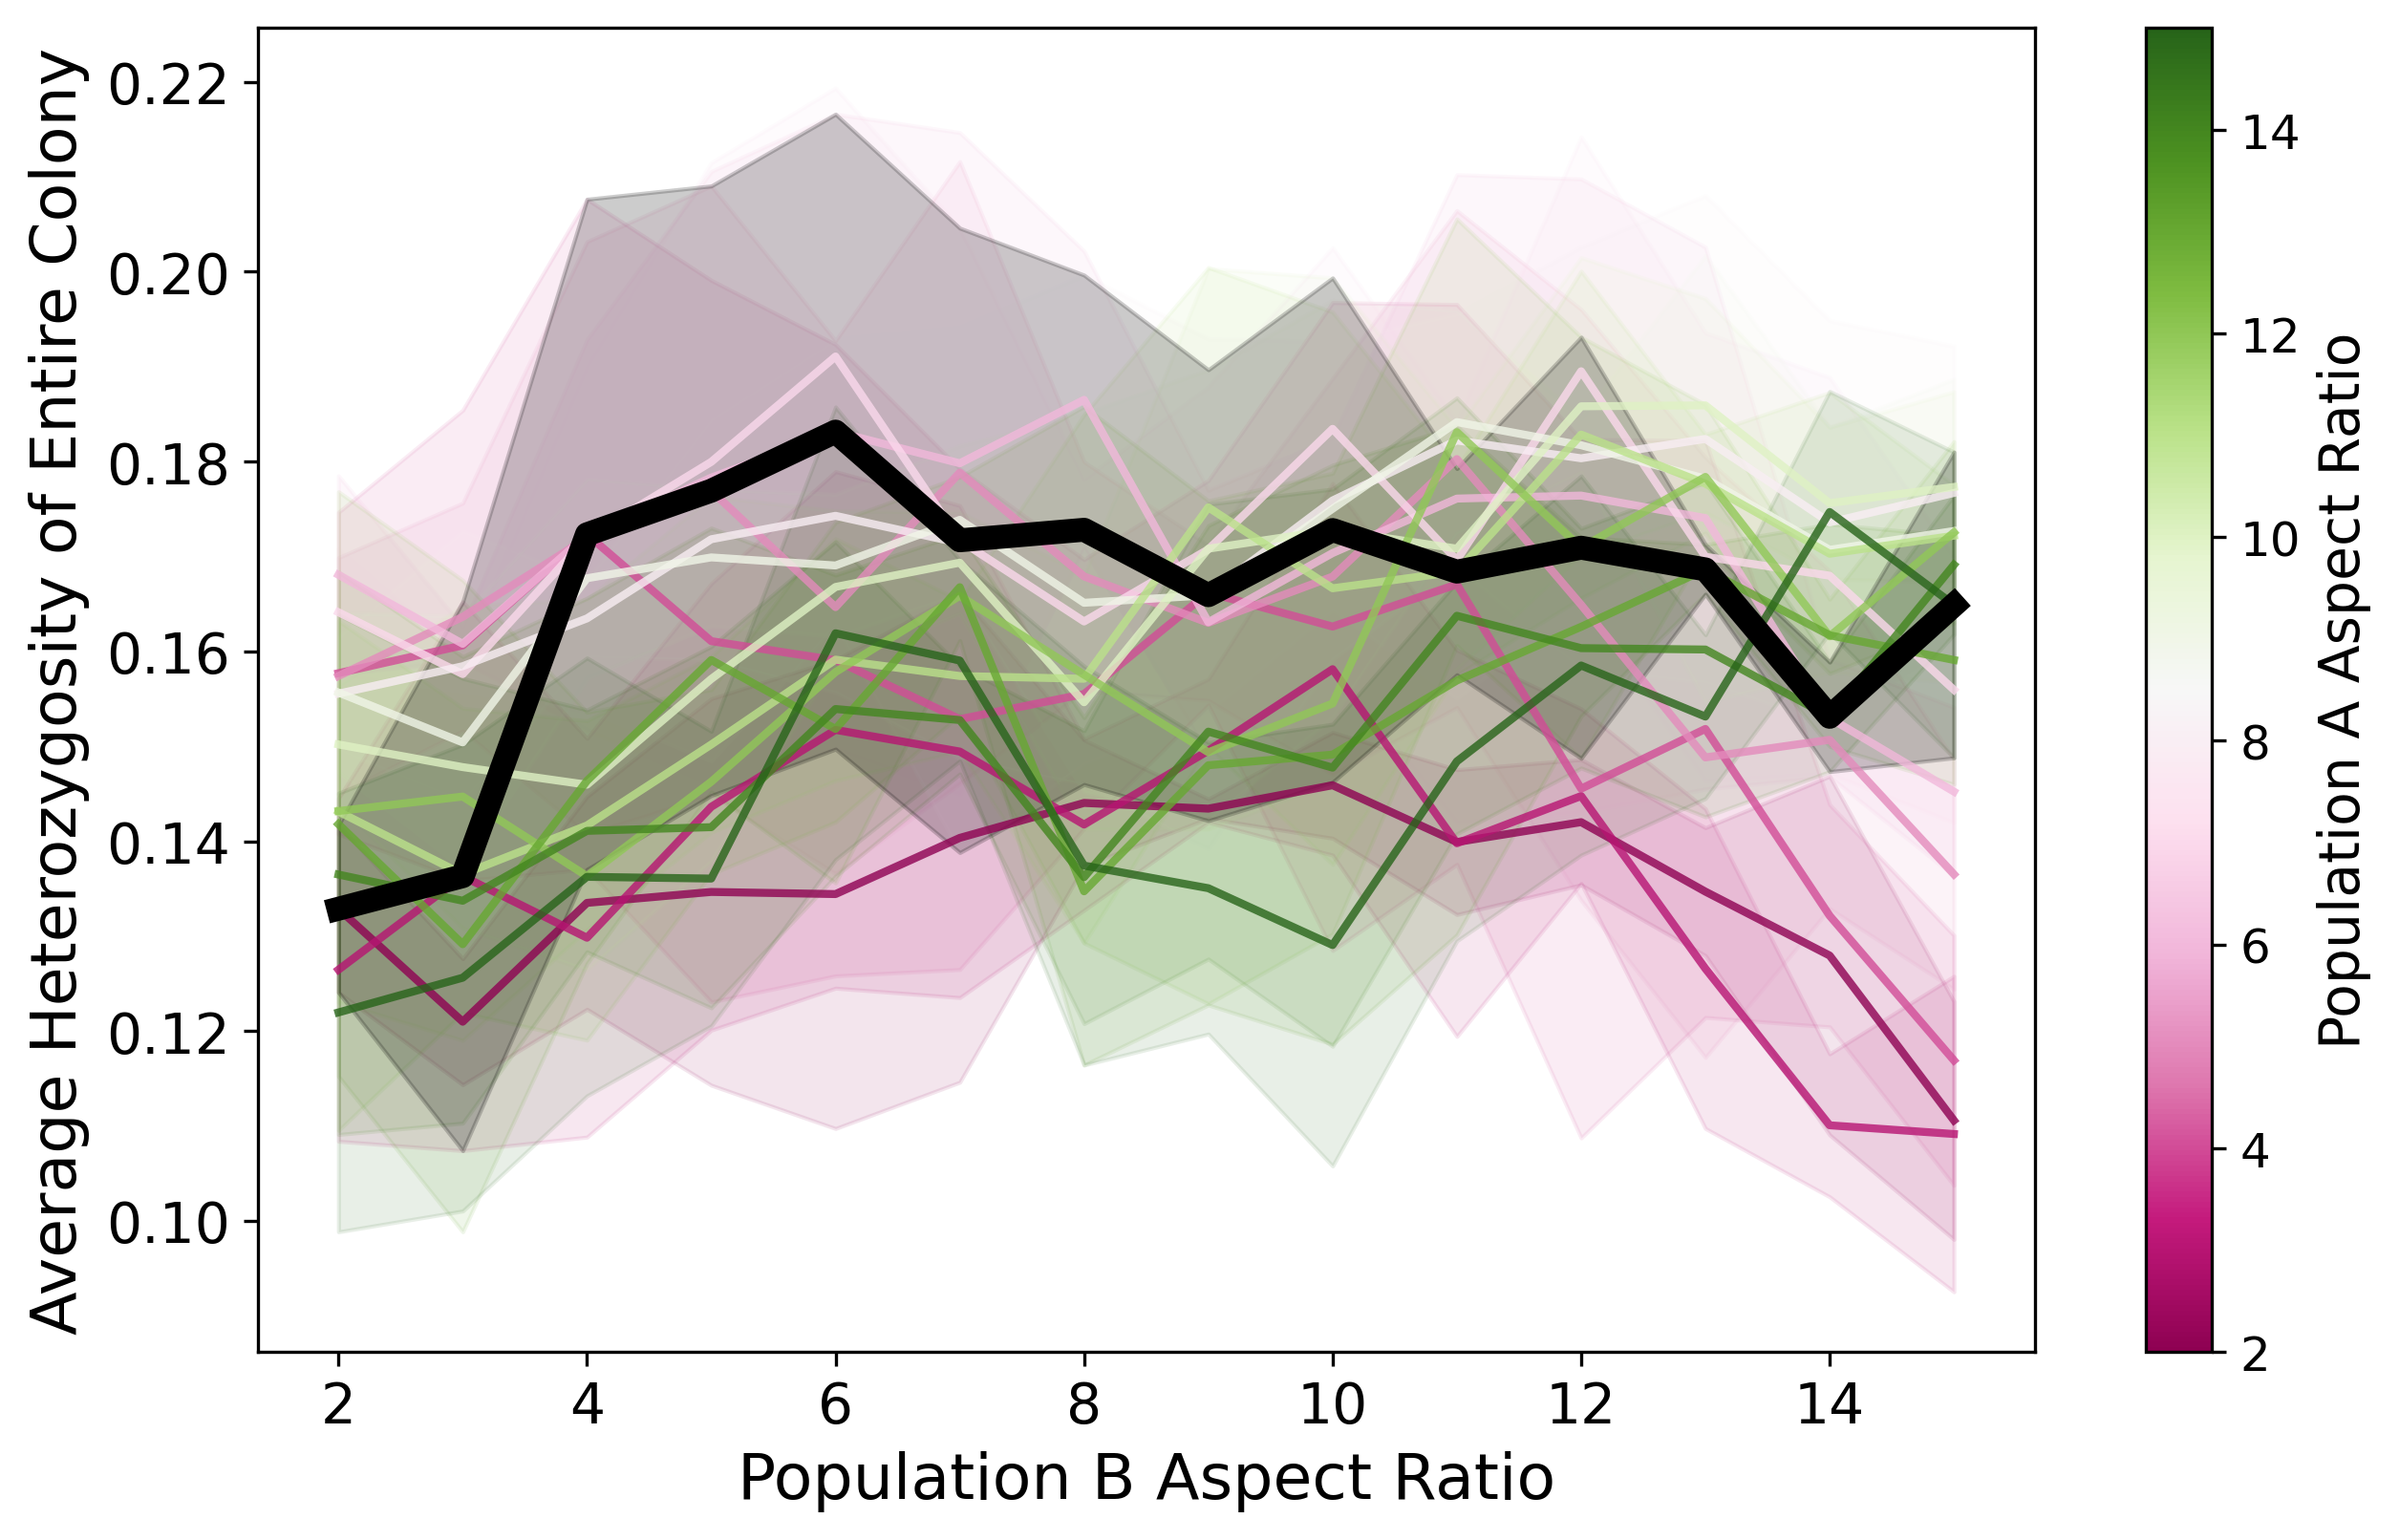

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


print("output_final structure:")
for idx, item in enumerate(output_final):
    print(f"output_final[{idx}] length: {len(item)} - {item}")


averages = []
std_deviations = []


for aspect_results in output_final:
    
    aspect_array = np.array([np.array(run_results) for idx, run_results in enumerate(aspect_results) 
                             if len(run_results) > 0 and not (idx == 1 or idx == 3)])
    
    if aspect_array.size > 0:
        avg = np.mean(aspect_array, axis=0)  
        std_dev = np.std(aspect_array, axis=0)  
    else:
        avg = np.array([])
        std_dev = np.array([])

    averages.append(avg)
    std_deviations.append(std_dev)

print("Averages:", averages)
print("Standard Deviations:", std_deviations)

num_lines = len(averages)

aspects = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
aspects_plotted = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


heterozygosity_matrix = np.full((len(aspects), len(aspects)), np.nan)  
for i in range(len(aspects)):
    for j in range(len(aspects)):
        try:
            heterozygosity_matrix[i, j] = (averages[i][j] + averages[j][i])/2
        except IndexError:
            continue  


from scipy.ndimage import gaussian_filter

plt.figure(figsize=(8, 6), dpi=300)
heatmap = plt.imshow(heterozygosity_matrix, interpolation='nearest', cmap='inferno', origin='lower')
cbar = plt.colorbar(heatmap)
cbar.ax.tick_params(labelsize=16)

Z_smooth = gaussian_filter(heterozygosity_matrix, sigma=1.5)
x_coords = np.arange(len(aspects))
y_coords = np.arange(len(aspects))
plt.contour(x_coords, y_coords, Z_smooth,
            levels=[0.15], colors='white', linewidths=2.5)

plt.xlabel('Population A Aspect Ratio', fontsize=16)
plt.ylabel('Population B Aspect Ratio', fontsize=16)
plt.xticks(ticks=np.arange(len(aspects)), labels=aspects, fontsize=16)
plt.yticks(ticks=np.arange(len(aspects)), labels=aspects, fontsize=16)

plt.savefig("Heterozygosity_Heatmap.png")
plt.show()


color_map = plt.get_cmap('PiYG')  


plt.figure(figsize=(10, 6), dpi=300)

avg_to_plot = [[]*num_lines]
std_to_plot = [[]*num_lines]
for i in range(num_lines):
    for j in range(num_lines):
        avg_to_plot.append((averages[i][j] + averages[j][i])/2)
        std_to_plot.append(np.sqrt((std_deviations[i][j]**2 / 5) + (std_deviations[j][i]**2 / 5)))



for i in range(num_lines):
    if len(averages[i]) > 0:
        color = color_map(i / (num_lines - 1))
        plt.plot(aspects, averages[i], linestyle='-', linewidth=2, color=color, alpha=0.8)
        plt.fill_between(
            aspects, 
            averages[i] - std_deviations[i], 
            averages[i] + std_deviations[i], 
            color=color, 
            alpha=0.1  
        )


equal_aspects = [averages[i][i] for i in range(len(aspects)) if len(averages[i]) > i]
equal_aspects_std = [std_deviations[i][i] for i in range(len(aspects)) if len(std_deviations[i]) > i]
plt.plot(aspects, equal_aspects, linestyle='-', linewidth=6, color='black', alpha=1)
plt.fill_between(
    aspects, 
    np.array(equal_aspects) - np.array(equal_aspects_std), 
    np.array(equal_aspects) + np.array(equal_aspects_std), 
    color='black', 
    alpha=0.2  
)


sm = plt.cm.ScalarMappable(cmap=color_map, norm=plt.Normalize(vmin=min(aspects), vmax=max(aspects)))
sm.set_array([])  
cbar = plt.colorbar(sm, ax=plt.gca())
cbar.set_label('Population A Aspect Ratio', fontsize=14)
cbar.ax.tick_params(labelsize=12)


plt.xlabel("Population B Aspect Ratio", fontsize=16)
plt.ylabel("Average Heterozygosity of Entire Colony", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.savefig("Heterozygosity_Final_Plot.png")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import colors
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable


class MidpointNormalize(colors.Normalize):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        self.midpoint = midpoint
        super().__init__(vmin, vmax, clip)

    def __call__(self, value, clip=None):
        result = np.ma.masked_array(np.interp(value, [self.vmin, self.midpoint, self.vmax], [0, 0.5, 1]))
        return result


plt.rcParams.update({
    'font.size': 14,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'axes.labelsize': 18,
    'axes.titlesize': 20,
    'legend.fontsize': 14,
})


averages = []
std_deviations = []


for aspect_results in output_final:
    aspect_array = np.array([np.array(run_results) for idx, run_results in enumerate(aspect_results) 
                             if len(run_results) > 0 and not (idx == 1 or idx == 3)])
    
    if aspect_array.size > 0:
        avg = np.mean(aspect_array, axis=0)
        std_dev = np.std(aspect_array, axis=0)
    else:
        avg = np.array([])
        std_dev = np.array([])

    averages.append(avg)
    std_deviations.append(std_dev)

num_lines = len(averages)

aspects = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


colors = sns.diverging_palette(150, 280, s=95, l=70, n=15, center="dark").as_hex()
colors[8] = "#0000FF"

color_map = ListedColormap(colors)
bounds = np.arange(2, 17, 1)
norm = BoundaryNorm(bounds, color_map.N)


plt.figure(figsize=(10, 6), dpi=300)

avg_to_plot = [[] for _ in range(len(aspects))]
std_to_plot = [[] for _ in range(len(aspects))]

for i in range(len(aspects)):
    for j in range(len(aspects)):
        avg_to_plot[i].append((averages[i][j] + averages[j][i]) / 2)
        std_to_plot[i].append(np.sqrt((std_deviations[i][j]**2 / 5) + (std_deviations[j][i]**2 / 5)))


for i in range(num_lines):
    if len(avg_to_plot[i]) > 0:
        color = color_map(norm(aspects[i]))
        avg_array = np.array(avg_to_plot[i])
        std_array = np.array(std_to_plot[i])
        
        plt.plot(aspects, avg_array, linestyle='-', linewidth=2, color=color, alpha=0.8)
        plt.fill_between(
            aspects, 
            avg_array - std_array,
            avg_array + std_array,
            color=color, 
            alpha=0.1
        )


equal_aspects = [avg_to_plot[i][i] for i in range(len(aspects)) if len(avg_to_plot[i]) > i]
equal_aspects_std = [std_to_plot[i][i] for i in range(len(aspects)) if len(std_to_plot[i]) > i]
plt.plot(aspects, equal_aspects, linestyle='-', linewidth=6, color='blue', alpha=1)
plt.fill_between(
    aspects, 
    np.array(equal_aspects) - np.array(equal_aspects_std), 
    np.array(equal_aspects) + np.array(equal_aspects_std), 
    color='black', 
    alpha=0.2
)


sm = ScalarMappable(cmap=color_map, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), boundaries=bounds, ticks=bounds + 0.5)
cbar.set_label('Population A Aspect Ratio', fontsize=16)
cbar.ax.tick_params(labelsize=18)
cbar.ax.set_yticklabels([str(int(i)) for i in bounds])

plt.xlabel("Population B Aspect Ratio", fontsize=14)
plt.ylabel("Average Heterozygosity of Entire Colony", fontsize=14)
plt.tick_params(labelsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.savefig("Heterozygosity_Final_Plot_Centered_Colorbar.png")
plt.show()


SyntaxError: unterminated string literal (detected at line 53) (788582129.py, line 53)